step1:import libraries


In [6]:
#import libraries
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns 



step2:load datasets


In [7]:
df = pd.read_csv("messy_sales - Sheet1.csv")

In [43]:
df.head(10)


,Date,Region,Product,Category,Units Sold,Unit Price,Total Sales,Profit Margin (%)
0,2024-01-15,North,Tablet,Electronics,32.000000,858.00,26096.323077,10.0
1,NaT,North,Tablet,Electronics,72.000000,833.83,26096.323077,15.0
2,NaT,East,Laptop,Elec,52.307692,489.12,26096.323077,8.0
3,NaT,West,Laptop,Gadget,52.307692,733.46,26096.323077,10.0
4,NaT,East,Phone,Elec,47.000000,373.00,26096.323077,10.0
5,2024-04-03,South,Laptop,Gadgets,52.307692,670.28,3103.000000,8.0
6,NaT,North,Tablet,Electronics,52.307692,758.58,26096.323077,8.0
7,2024-03-15,West,Tablet,Gadgets,47.000000,241.65,26096.323077,12.0
8,2024-01-09,West,Phone,Gadget,52.307692,796.00,26096.323077,8.0
9,NaT,West,Laptop,Gadgets,52.307692,996.92,26096.323077,8.0


step3: check for missing data and info


In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Date               65 non-null     datetime64[ns]
 1   Region             200 non-null    object        
 2   Product            200 non-null    object        
 3   Category           200 non-null    object        
 4   Units Sold         200 non-null    float64       
 5   Unit Price         200 non-null    float64       
 6   Total Sales        200 non-null    float64       
 7   Profit Margin (%)  200 non-null    float64       
dtypes: datetime64[ns](1), float64(4), object(3)
memory usage: 12.6+ KB


step 3.5: handle missing value

In [45]:
df.isnull().sum()

Date                 135
Region                 0
Product                0
Category               0
Units Sold             0
Unit Price             0
Total Sales            0
Profit Margin (%)      0
dtype: int64

Ensure numeric columns are numeric before filling NaN

In [46]:
df["Units Sold"] = pd.to_numeric(df["Units Sold"], errors = "coerce")
df["Total Sales"] = pd.to_numeric(df["Total Sales"], errors = "coerce")

fill missing numeric values with the column mean


In [47]:
df["Units Sold"]=df["Units Sold"].fillna(df["Units Sold"].mean())
df["Total Sales"]=df["Total Sales"].fillna(df["Total Sales"].mean())

Clean column names(remove loading/ trailing spaces)

In [48]:
df.columns=df.columns.str.strip()

fix data formate (turn inconsistent text into real data formate)

In [49]:
df["Date"]=pd.to_datetime(df["Date"], errors="coerce")

Standradize text column (make name consistent and neat)

In [50]:
for col in ["Region","Product","Category"]:
    df[col]=df[col].str.strip().str.title()

Convert units Sold to numeric (turn words like twenty into NaN)

In [51]:
df["Units Sold"]=pd.to_numeric(df["Units Sold"], errors="coerce")

Clean currency column (units sold, Total Sales)

In [52]:
for col in ["Unit Price", "Total Sales"]:

    df[col] = df[col].astype(str)
    df[col] = (

    df[col].str.replace("[$,USD]","",regex= True).str.strip()
    )
    df[col] =pd.to_numeric (df[col], errors="coerce")

fix Profit Margin(%)
Some values are like 10%, 0.10 or 10 percent -let's make them constant pi

In [53]:
df["Profit Margin (%)"] = (
    df["Profit Margin (%)"].astype(str).str.replace("%","",regex = True)
    .str.replace("percent","", regex= True)
    .astype(float)
)

df["Profit Margin (%)"] =np.where(df["Profit Margin (%)"]<1, df["Profit Margin (%)" ]* 100 , df["Profit Margin (%)"])

Drop rows with missing key data (Clean final dataset)

In [54]:
df_cleaned =df.dropna(subset=["Date", "Total Sales", "Region"])

check cleaned result


In [42]:
df_cleaned.head()

,Date,Region,Product,Category,Units Sold,Unit Price,Total Sales,Profit Margin (%)
0,2024-01-15,North,Tablet,Electronics,32.000000,858.00,26096.323077,10.0
5,2024-04-03,South,Laptop,Gadgets,52.307692,670.28,3103.000000,8.0
7,2024-03-15,West,Tablet,Gadgets,47.000000,241.65,26096.323077,12.0
8,2024-01-09,West,Phone,Gadget,52.307692,796.00,26096.323077,8.0
10,2024-01-26,South,Desktop,Elec,52.307692,100.76,26096.323077,8.0


Toatl sales by Region

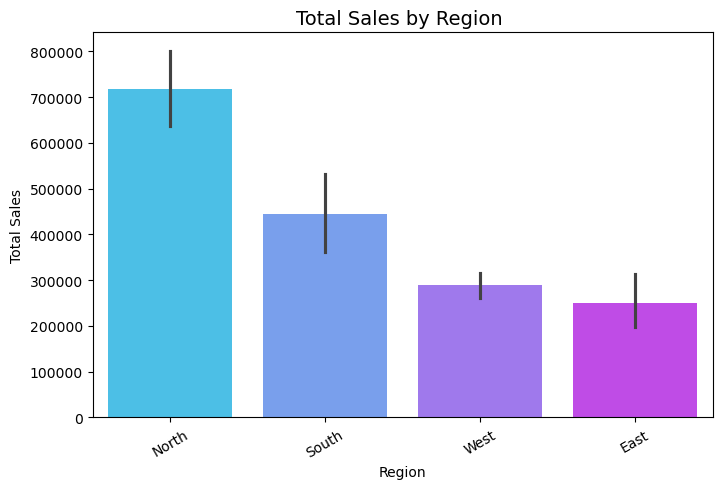

In [58]:
plt.figure(figsize=(8,5))
sns.barplot(data=df_cleaned, x="Region", y="Total Sales", estimator = sum, palette = "cool")
plt.title("Total Sales by Region ", fontsize = 14)
plt.xticks(rotation =30)
plt.show()

Sale trend over time

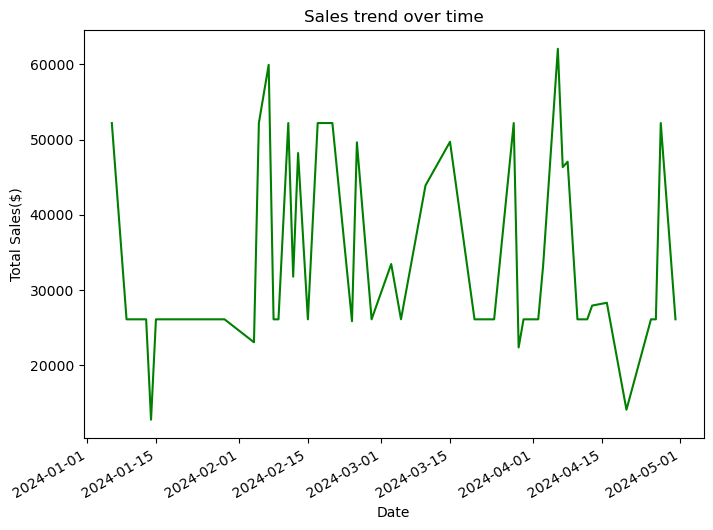

In [63]:
plt.figure(figsize=(8,6))
df_cleaned.groupby("Date") ["Total Sales"].sum().plot(kind="line", color="green")
plt.title("Sales trend over time")
plt.ylabel("Total Sales($)")
plt.show()

Category share pie chart

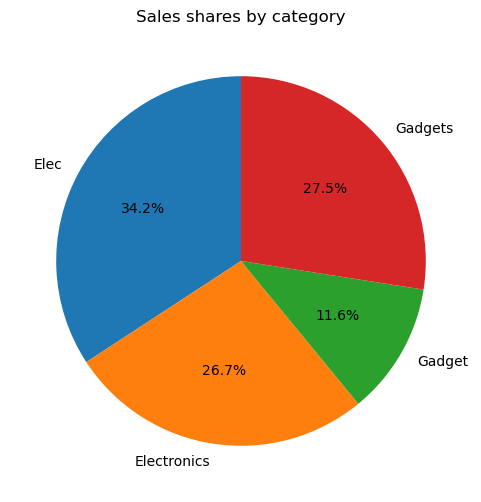

In [67]:
plt.figure(figsize=(6,6))
category_sales = df_cleaned.groupby("Category")["Total Sales"].sum()
category_sales.plot(kind="pie", autopct="%1.1f%%",startangle=90, color= sns.color_palette("pastel"))
plt.title("Sales shares by category")
plt.ylabel("")
plt.show()